# Who wants to be a PoliMillionaire? â€” Structured Analysis

**Group members:** [names and emails here]

**Video:** [link here]

**Coding assistants used:** Claude Code (Anthropic)

---

This notebook runs **`NUM_RUNS` games per competition** with full per-question logging (raw LLM output, chosen option, correctness) and provides performance analysis across all runs.

The game loop cells collect data; the analysis cells at the bottom can be re-run independently.

## 1. Imports

In [321]:
import json
import os
import sys
import time
from pathlib import Path
from datetime import datetime

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import torch
from transformers import pipeline
import dotenv
from IPython.display import display

## 2. Environment Detection (Colab / Local)

In [322]:
IN_COLAB = False
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    pass

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive/NLP_project')
else:
    BASE_DIR = Path('./')

RUNS_DIR = BASE_DIR / 'data' / 'runs'
RUNS_DIR.mkdir(parents=True, exist_ok=True)
print('Environment:', 'COLAB' if IN_COLAB else 'LOCAL')
print('Runs directory:', RUNS_DIR)

Environment: LOCAL
Runs directory: data\runs


## 3. API Setup

In [323]:
package_parent_dir = os.path.abspath('./')
if package_parent_dir not in sys.path:
    sys.path.append(package_parent_dir)

from millionaire_client import MillionaireClient, AuthenticationError
dotenv.load_dotenv()

username = os.getenv('USER')
pwd = os.getenv('PASSWORD')
API_URL = 'http://131.175.15.22:51111/'

client = MillionaireClient(API_URL)
try:
    user = client.login(username, pwd)
    print('Login successful. Welcome,', user.username)
except AuthenticationError as e:
    print('Login failed:', e)

Login successful. Welcome, Alisss


## 4. Run Configuration

Change these variables for each experiment.

In [324]:
MODEL_NAME  = 'Qwen/Qwen2.5-1.5B-Instruct'  # public model, no auth needed
REASONING   = False                        # True to enable thinking mode
NUM_RUNS    = 5                            # game repetitions per competition
RUN_COMMENT = 'Baseline zero-shot greedy' # free-text description of this experiment
TECHNIQUES  = ['zero-shot', 'greedy']     # list of techniques used

MAX_LEVELS = 15  # max levels for all competitions

## 5. Logging Functions

In [ ]:
def _sanitize(text, max_len=24):
    # Safe for filesystem, the name must be
    return ''.join(c if c.isalnum() or c in '_-' else '_' for c in text)[:max_len].strip('_')


def create_run_folder(model_name, comment):
    ts = datetime.now().strftime('%d%m%Y%H%M')
    name = _sanitize(model_name) + '_' + ts
    run_dir = RUNS_DIR / name
    run_dir.mkdir(parents=True, exist_ok=True)
    print('Run folder created:', run_dir.name)
    return run_dir


def save_metadata(run_dir, model_name, reasoning, comment, techniques, num_runs):
    # Write run_info.json early so metadata survives a mid-run crash
    meta = {
        'model_name': model_name,
        'reasoning': reasoning,
        'comment': comment,
        'techniques': techniques,
        'timestamp': datetime.now().isoformat(),
        'num_runs_per_competition': num_runs,
    }
    with open(run_dir / '.run_info.json', 'w', encoding='utf-8') as f:
        json.dump(meta, f, indent=2)
    return meta


def compute_competition_summary(attempts_log):
    # Accuracy = correct / (num_attempts * max_levels)
    # Penalizes early exits: finishing at level 5 of 15 contributes 4/15, not 4/4
    total_q = total_l = correct_q = timeout_q = 0
    total_time = 0.0
    all_earned = []
    max_level_reached = 0
    for attempt in attempts_log:
        max_level_reached = attempt['final_level'] if attempt['final_level']> max_level_reached else max_level_reached
        total_l += attempt['final_level']
        all_earned.append(attempt['earned'])
        for q in attempt['questions']:
            total_q += 1
            total_time += q['time']
            if q['timed_out']:
                timeout_q += 1
            elif q['correct'] is True:
                correct_q += 1
    denominator = len(attempts_log) * MAX_LEVELS  
    return {
        'total_attempts': len(attempts_log),
        'total_questions_answered': total_q,
        'avg_level': round(total_l / len(attempts_log), 2) if attempts_log else 0,
        'max_level': max_level_reached,
        'avg_earned': round(sum(all_earned) / len(all_earned), 2) if all_earned else 0,
        'max_earned': max(all_earned) if all_earned else 0,
        'accuracy': round(correct_q / denominator, 4) if denominator > 0 else 0,
        'timeout_count': timeout_q,
        'avg_time_per_question': round(total_time / total_q, 4) if total_q > 0 else 0,
        'max_time': round(max(q['time'] for attempt in attempts_log for q in attempt['questions']), 4) if total_q > 0 else 0,
    }


def save_competition_result(run_dir, comp, attempts_log):
    filename = 'comp_' + str(comp.id) + '_' + _sanitize(comp.name) + '.json'
    data = {
        'competition_id': comp.id,
        'competition_name': comp.name,
        'summary': compute_competition_summary(attempts_log),
        'attempts': attempts_log,
    }
    with open(run_dir / filename, 'w', encoding='utf-8') as f:
        json.dump(data, f, indent=2, ensure_ascii=False)
    print('  Saved:', filename)


def save_run_summary(run_dir, all_comp_data, metadata):
    total_attempts = total_questions = correct_total = 0
    denominator_total = 0
    all_earned = []
    per_comp = {}
    for comp_id, comp_info in all_comp_data.items():
        s = compute_competition_summary(comp_info['attempts'])
        per_comp[str(comp_id)] = {
            'name': comp_info['name'],
            'accuracy': s['accuracy'],
            'avg_level': s['avg_level'],
            'avg_earned': s['avg_earned'],
        }
        total_attempts += s['total_attempts']
        total_questions += s['total_questions_answered']
        denominator_total += s['total_attempts'] * comp_info['max_levels']
        for attempt in comp_info['attempts']:
            all_earned.append(attempt['earned'])
            for q in attempt['questions']:
                if q['correct'] is True:
                    correct_total += 1
    run_info = {
        **metadata,
        'total_competitions': len(all_comp_data),
        'overall_accuracy': round(correct_total / denominator_total, 4) if denominator_total > 0 else 0,
        'comp_info': per_comp,
    }
    with open(run_dir / '.run_info.json', 'w', encoding='utf-8') as f:
        json.dump(run_info, f, indent=2)
    print('  Saved: .run_info.json')
    return run_info


def update_runs_log(runs_dir, run_folder, run_info):
    log_path = runs_dir / 'runs_log.json'
    entries = []
    if log_path.exists():
        with open(log_path, 'r', encoding='utf-8') as f:
            entries = json.load(f)
    competition_summary = {
        info['name']: info['accuracy']
        for info in run_info['comp_info'].values()
    }
    entries.append({
        'run_folder':            run_folder,
        'model_name':            run_info['model_name'],
        'total_runs':            run_info['num_runs_per_competition'],
        'overall_accuracy':      run_info['overall_accuracy'],
        'reasoning':             run_info['reasoning'],
        'comment':               run_info['comment'],
        'techniques':            run_info['techniques'],
        'competition_accuracy':  competition_summary,
    })
    with open(log_path, 'w', encoding='utf-8') as f:
        json.dump(entries, f, indent=2)
    print('runs_log.json updated -', len(entries), 'runs logged')

## 6. Model Loading

In [326]:
print('Loading model:', MODEL_NAME)
print('This may take a few minutes on first run...')
llm_pipeline = pipeline(
    'text-generation',
    model=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map='auto',
    trust_remote_code=False,
)
print('Model loaded!')

Loading model: Qwen/Qwen2.5-1.5B-Instruct
This may take a few minutes on first run...


Loading weights: 100%|██████████| 338/338 [00:00<00:00, 12995.70it/s]


Model loaded!


## 7. LLM Strategy

In [327]:
class LLMStrategy:
    def __init__(self, enable_thinking=False):
        self.enable_thinking    = enable_thinking
        self.last_raw_output    = None
        self.last_chosen_letter = None
        self.last_chosen_text   = None

    def __call__(self, question):
        if not question or not question.options:
            raise ValueError('No question or options provided')

        letters = ['A', 'B', 'C', 'D']
        opts = question.options[:4]

        # Build prompt - the question and options, format we must
        lines = ['Question: ' + question.text, 'Options:']
        for i, opt in enumerate(opts):
            lines.append(letters[i] + ': ' + opt.text)
        lines.append('Answer with just the letter of the correct option (A, B, C, or D).')
        lines.append('Answer:')
        prompt = chr(10).join(lines)

        messages = [{'role': 'user', 'content': prompt}]
        try:
            prompt_text = llm_pipeline.tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                enable_thinking=self.enable_thinking,
                add_generation_prompt=True,
            )
        except Exception:
            prompt_text = prompt

        max_new = 512 if self.enable_thinking else 10
        outputs = llm_pipeline(
            prompt_text,
            max_new_tokens=max_new,
            do_sample=False,
            return_full_text=False,
        )

        generated = outputs[0]['generated_text'].strip()
        self.last_raw_output = generated

        # After </think> the final answer lives — find it we must
        answer_part = generated.split('</think>')[-1].strip() if '</think>' in generated else generated

        chosen_letter = None
        first_char = answer_part.strip()[:1].upper()
        if first_char in letters:
            chosen_letter = first_char
        else:
            # Fallback: reverse scan of full output
            for c in reversed(generated.upper()):
                if c in letters:
                    chosen_letter = c
                    break

        if chosen_letter is not None:
            idx = letters.index(chosen_letter)
            self.last_chosen_letter = chosen_letter
            self.last_chosen_text   = opts[idx].text
            return opts[idx].id

        # Last resort fallback — first option, choose we do
        print('WARNING: no letter parsed from output:', repr(generated[:60]))
        self.last_chosen_letter = '?'
        self.last_chosen_text   = opts[0].text
        return opts[0].id

## 8. Game Loop

Run this cell to execute `NUM_RUNS` games for each competition. Results are saved incrementally â€” safe to interrupt and re-run.

In [328]:
# Create run folder and save metadata â€" the journey begins here
run_dir  = create_run_folder(MODEL_NAME, RUN_COMMENT)
metadata = save_metadata(run_dir, MODEL_NAME, REASONING, RUN_COMMENT, TECHNIQUES, NUM_RUNS)

comps = client.competitions.list_all()
print('Competitions found:', len(comps))
all_comp_data = {}

for comp in comps:
    print()
    print('=' * 60)
    print('Competition', comp.id, ':', comp.name, '| max_levels:', comp.max_levels)
    attempts_log = []

    for run_idx in range(1, NUM_RUNS + 1):
        print('  Run', run_idx, '/', NUM_RUNS, '...', end=' ', flush=True)
        session  = client.game.start(comp.id)
        strategy = LLMStrategy(enable_thinking=REASONING)
        questions_log = []
        max_time = 0.0

        current_level = 0
        last_correct_level = 0

        while session.in_progress:
            question = session.current_question
            if question is None:
                break

            letters = ['A', 'B', 'C', 'D']
            opts    = question.options[:4]
            options_dict = {letters[i]: opts[i].text for i in range(len(opts))}

            # Capture level and prize from GameState before answering â€"
            # question.level defaults to 0 when the API omits the field
            current_level = session.state.current_level
            current_prize = next(
                (ml.amount for ml in session.state.money_pyramid if ml.level == current_level),
                None
            )

            t0 = time.time()
            option_id = strategy(question)
            result    = session.answer(option_id)
            elapsed   = time.time() - t0
            if elapsed > max_time:
                max_time = elapsed

            if result.correct:
                last_correct_level = current_level

            questions_log.append({
                'level':          current_level,
                'prize':          current_prize,
                'question_text':  question.text,
                'options':        options_dict,
                'llm_raw_output': strategy.last_raw_output,
                'chosen_letter':  strategy.last_chosen_letter,
                'correct':        result.correct,
                'timed_out':      result.timed_out,
                'time':           elapsed,
            })

        earned = session.earned_amount
        print(
            'earned=' + str(earned)
            + ', q=' + str(len(questions_log))
            + ', max_t=' + '{:.2f}'.format(max_time) + 's'
        )
        attempts_log.append({
            'attempt':     run_idx,
            'earned':      earned,
            'final_level': last_correct_level,
            'questions':   questions_log,
        })

    save_competition_result(run_dir, comp, attempts_log)
    all_comp_data[comp.id] = {
        'name':       comp.name,
        'max_levels': comp.max_levels,
        'attempts':   attempts_log,
    }

run_info = save_run_summary(run_dir, all_comp_data, metadata)
update_runs_log(RUNS_DIR, run_dir.name, run_info)
print()
print('Run complete! Overall accuracy:', '{:.1%}'.format(run_info['overall_accuracy']))

Run folder created: Qwen_Qwen2_5-1_5B-Instru_110520260047
Competitions found: 4

Competition 0 : Entertainment | max_levels: 15
  Run 1 / 5 ... 

[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs

earned=8000, q=9, max_t=0.84s
  Run 2 / 5 ... 

[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


earned=200, q=3, max_t=0.56s
  Run 3 / 5 ... 

...

earned=0, q=1, max_t=0.44s
  Run 4 / 5 ... 

[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


earned=100, q=2, max_t=0.44s
  Run 5 / 5 ... 

[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


earned=100, q=2, max_t=0.60s
  Saved: comp_3_Maths.json
  Saved: .run_info.json
runs_log.json updated - 1 runs logged

Run complete! Overall accuracy: 19.0%


---

## 9. Analysis

The cells below are read-only and can be re-run at any time without touching the game loop.

In [329]:
# Load global runs log â€" all experiments, listed they are
log_path = RUNS_DIR / 'runs_log.json'
if not log_path.exists():
    print('No runs_log.json found. Run the game loop first.')
else:
    with open(log_path) as f:
        runs_log = json.load(f)
    df_runs = pd.DataFrame(runs_log)
    cols = ['run_folder', 'model_name', 'comment', 'techniques',
            'total_runs', 'overall_accuracy', 'avg_earned_per_attempt']
    display(df_runs[[c for c in cols if c in df_runs.columns]])

,run_folder,model_name,comment,techniques,total_runs,overall_accuracy
0,Qwen_Qwen2_5-1_5B-Instru_110520260047,Qwen/Qwen2.5-1.5B-Instruct,Baseline zero-shot greedy,"[zero-shot, greedy]",5,0.19


In [330]:
# Select which run to analyze â€" change ANALYZE_RUN to any run_folder from the table
ANALYZE_RUN = runs_log[-1]['run_folder']   # defaults to most recent
run_path = RUNS_DIR / ANALYZE_RUN

with open(run_path / '.run_info.json') as f:
    run_meta = json.load(f)

print('Analyzing run :', ANALYZE_RUN)
print('Model         :', run_meta['model_name'])
print('Reasoning     :', run_meta['reasoning'])
print('Comment       :', run_meta['comment'])
print('Techniques    :', run_meta['techniques'])
print('Runs/comp     :', run_meta['num_runs_per_competition'])
print('Overall acc.  :', '{:.1%}'.format(run_meta.get('overall_accuracy', float('nan'))))
print('Avg earned    :', '{:.0f}'.format(run_meta.get('avg_earned_per_attempt', float('nan'))))

Analyzing run : Qwen_Qwen2_5-1_5B-Instru_110520260047
Model         : Qwen/Qwen2.5-1.5B-Instruct
Reasoning     : False
Comment       : Baseline zero-shot greedy
Techniques    : ['zero-shot', 'greedy']
Runs/comp     : 5
Overall acc.  : 19.0%
Avg earned    : nan


In [331]:
# Build flat per-question DataFrame â€” one row per question answered
records = []
for json_file in sorted(run_path.glob('comp_*.json')):
    with open(json_file, encoding='utf-8') as f:
        comp_data = json.load(f)
    for attempt in comp_data['attempts']:
        for q in attempt['questions']:
            records.append({
                'comp_id':       comp_data['competition_id'],
                'comp_name':     comp_data['competition_name'],
                'attempt':       attempt['attempt'],
                'earned':        attempt['earned'],
                'level':         q['level'],
                'question_text': q['question_text'],
                'chosen_letter': q['chosen_letter'],
                'correct':       q['correct'],
                'timed_out':     q['timed_out'],
                'time':          q['time'],
            })

df = pd.DataFrame(records)
print('Total question records :', len(df))
print('Competitions           :', df['comp_name'].nunique())
print('Runs per competition   :', run_meta['num_runs_per_competition'])
print('Overall accuracy       :', '{:.1%}'.format(df[~df['timed_out']]['correct'].mean()))
df.head()

Total question records : 77
Competitions           : 4
Runs per competition   : 5
Overall accuracy       : 74.0%


,comp_id,comp_name,attempt,earned,level,question_text,chosen_letter,correct,timed_out,time
0,0,Entertainment,1,8000,1,How does Drake's musical style differ from tha...,C,True,False,0.844419
1,0,Entertainment,1,8000,2,What is the primary concept of The Matrix that...,B,True,False,0.437952
2,0,Entertainment,1,8000,3,Which of the following best describes the rela...,A,True,False,0.613325
3,0,Entertainment,1,8000,4,How does the album 'OK Computer' differ from '...,B,True,False,0.585925
4,0,Entertainment,1,8000,5,Which of the following best describes the main...,C,True,False,0.461762


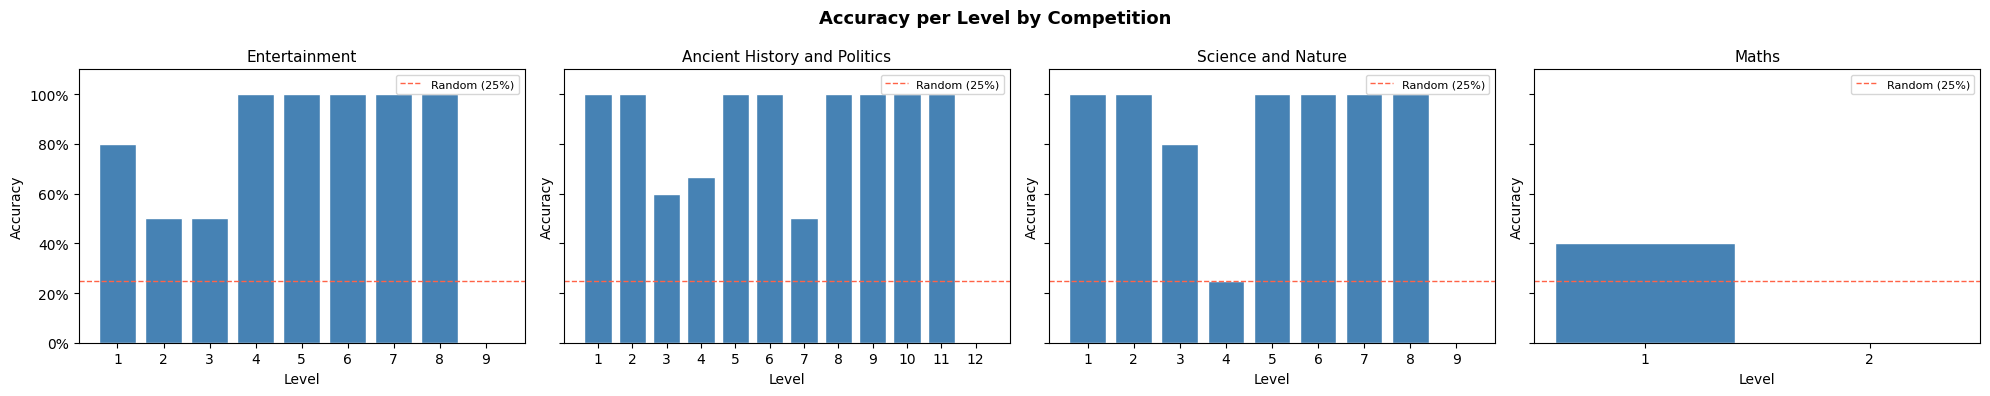

In [332]:
# Accuracy per level by competition
n_comps = df['comp_id'].nunique()
fig, axes = plt.subplots(1, max(1, n_comps), figsize=(5 * n_comps, 4), sharey=True)
if n_comps == 1:
    axes = [axes]

for ax, (comp_id, grp) in zip(axes, df.groupby('comp_id')):
    answerable = grp[~grp['timed_out']]
    acc = answerable.groupby('level')['correct'].mean()
    ax.bar(acc.index.astype(str), acc.values, color='steelblue', edgecolor='white')
    ax.axhline(0.25, color='tomato', linestyle='--', linewidth=1.0, label='Random (25%)')
    ax.set_title(grp['comp_name'].iloc[0], fontsize=11)
    ax.set_xlabel('Level')
    ax.set_ylabel('Accuracy')
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.set_ylim(0, 1.1)
    ax.legend(fontsize=8)

fig.suptitle('Accuracy per Level by Competition', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

C:\Users\andre\AppData\Local\Temp\ipykernel_25628\1945776103.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(earned_by_comp, labels=comp_labels, patch_artist=True)


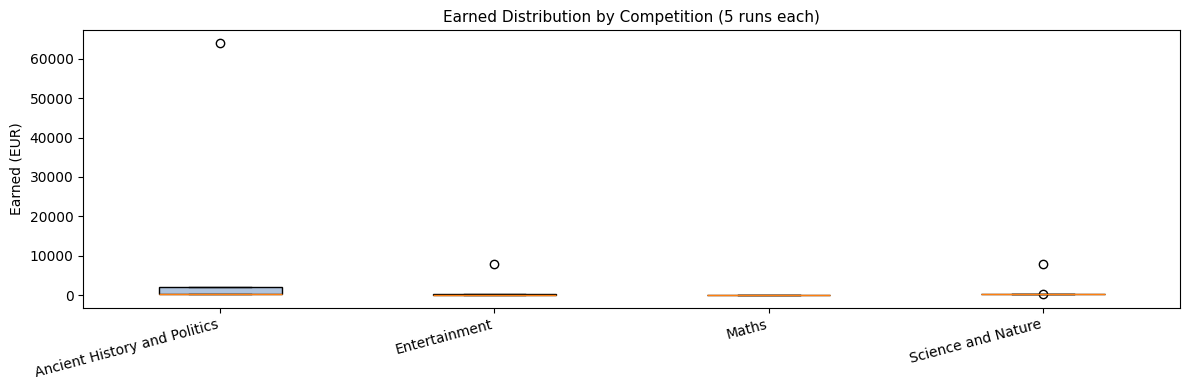

In [333]:
# Earned amount distribution per competition across all runs
df_attempts = df.drop_duplicates(subset=['comp_id', 'attempt'])[['comp_id', 'comp_name', 'attempt', 'earned']]
earned_by_comp = []
comp_labels = []
for comp_name, grp in df_attempts.groupby('comp_name'):
    earned_by_comp.append(grp['earned'].values)
    comp_labels.append(comp_name)

fig, ax = plt.subplots(figsize=(max(6, 3 * len(comp_labels)), 4))
bp = ax.boxplot(earned_by_comp, labels=comp_labels, patch_artist=True)
for patch in bp['boxes']:
    patch.set_facecolor('lightsteelblue')
ax.set_ylabel('Earned (EUR)')
title = 'Earned Distribution by Competition (' + str(run_meta['num_runs_per_competition']) + ' runs each)'
ax.set_title(title, fontsize=11)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

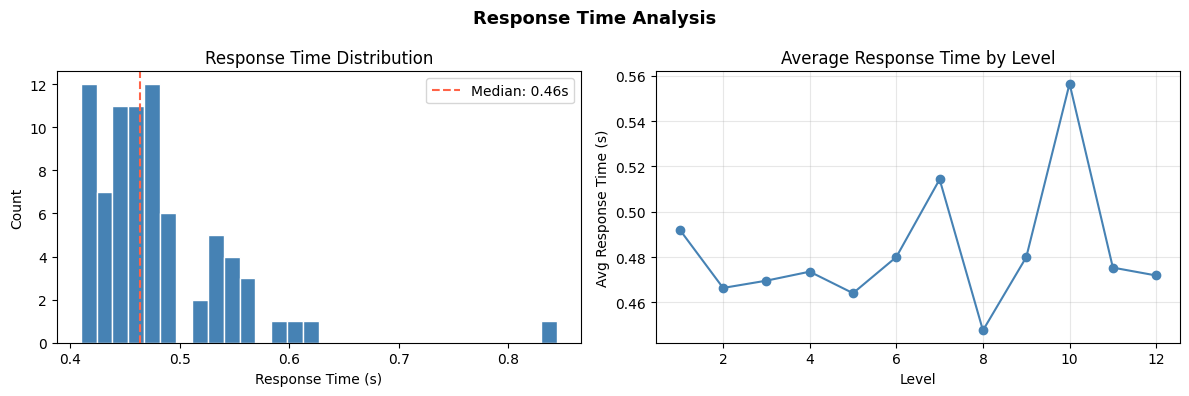

Min time  : 0.41s
Max time  : 0.84s
Mean time : 0.48s


In [334]:
# Response time analysis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.hist(df['time'].values, bins=30, color='steelblue', edgecolor='white')
median_t = df['time'].median()
ax1.axvline(median_t, color='tomato', linestyle='--',
            label='Median: ' + '{:.2f}'.format(median_t) + 's')
ax1.set_xlabel('Response Time (s)')
ax1.set_ylabel('Count')
ax1.set_title('Response Time Distribution')
ax1.legend()

avg_t = df.groupby('level')['time'].mean()
ax2.plot(avg_t.index, avg_t.values, marker='o', color='steelblue')
ax2.set_xlabel('Level')
ax2.set_ylabel('Avg Response Time (s)')
ax2.set_title('Average Response Time by Level')
ax2.grid(True, alpha=0.3)

plt.suptitle('Response Time Analysis', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Min time  :', '{:.2f}'.format(df['time'].min()) + 's')
print('Max time  :', '{:.2f}'.format(df['time'].max()) + 's')
print('Mean time :', '{:.2f}'.format(df['time'].mean()) + 's')

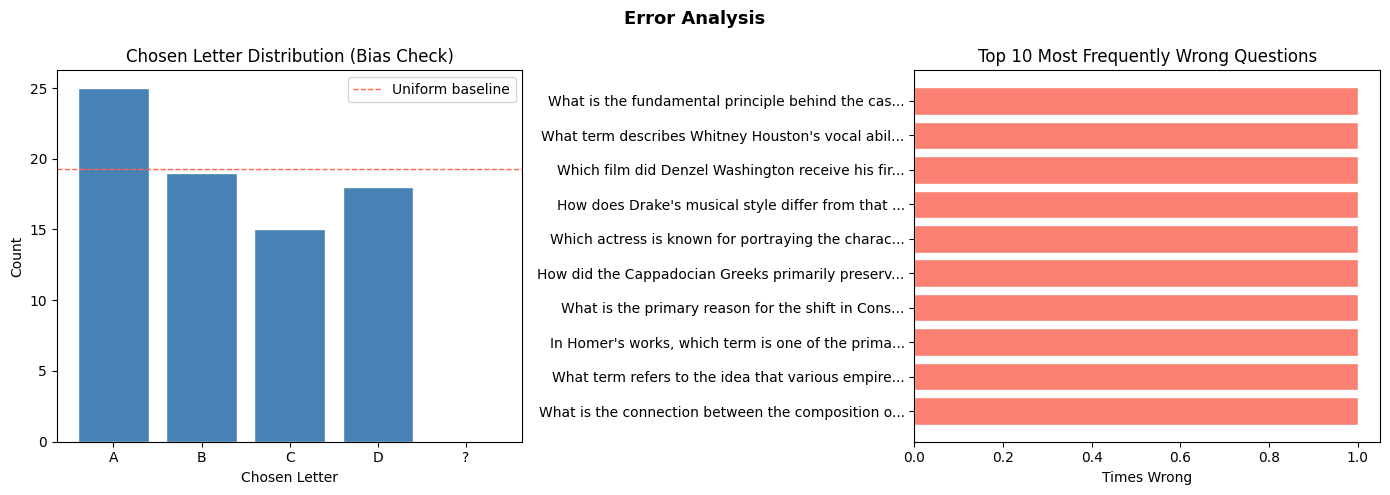

Timeouts         : 0
Correct answers  : 57
Wrong answers    : 20
Unknown (timeout): 0


In [335]:
# Error analysis: letter bias + most frequently wrong questions
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Letter distribution â€” bias reveal, this chart will
all_letters = ['A', 'B', 'C', 'D', '?']
letter_counts = df['chosen_letter'].value_counts().reindex(all_letters, fill_value=0)
ax1.bar(letter_counts.index, letter_counts.values, color='steelblue', edgecolor='white')
ax1.axhline(len(df) / 4, color='tomato', linestyle='--', linewidth=1.0, label='Uniform baseline')
ax1.set_title('Chosen Letter Distribution (Bias Check)')
ax1.set_xlabel('Chosen Letter')
ax1.set_ylabel('Count')
ax1.legend()

# Most frequently wrong questions
wrong = df[df['correct'] == False]
if len(wrong) > 0:
    wrong_counts = wrong['question_text'].value_counts().head(10)
    short_labels = [q[:48] + '...' if len(q) > 48 else q for q in wrong_counts.index]
    ax2.barh(short_labels, wrong_counts.values, color='salmon', edgecolor='white')
    ax2.set_title('Top 10 Most Frequently Wrong Questions')
    ax2.set_xlabel('Times Wrong')
    ax2.invert_yaxis()
else:
    ax2.text(0.5, 0.5, 'No wrong answers recorded!', ha='center', va='center', fontsize=13)
    ax2.set_title('Wrong Questions Analysis')

plt.suptitle('Error Analysis', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Timeouts         :', df['timed_out'].sum())
print('Correct answers  :', (df['correct'] == True).sum())
print('Wrong answers    :', (df['correct'] == False).sum())
print('Unknown (timeout):', df['correct'].isna().sum())